In [6]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_cohere import ChatCohere
from dotenv import load_dotenv

In [7]:
load_dotenv()

True

In [8]:
class SubState(TypedDict):
    input_text: str
    translated_text: str

In [9]:
subgraph_llm = ChatCohere(model="command-a-03-2025")

In [11]:
def translate_text(state: SubState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["input_text"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translated_text}

In [12]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [17]:
class ParentState(TypedDict):
    question: str
    answer_eng: str
    answer_hin: str

In [18]:
parent_llm = ChatCohere(model="command-a-03-2025")

In [20]:
def generate_answer(state: ParentState):
    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [22]:
def translate_answer(state: ParentState):
    # call the subgraph
    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [23]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

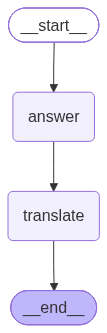

In [24]:
graph = parent_builder.compile()

graph

In [25]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': 'Quantum physics, also known as quantum mechanics, is a fundamental theory in physics that describes the behavior of matter and energy at the smallest scales, such as atoms and subatomic particles (e.g., electrons, photons, and quarks). It differs significantly from classical physics, which governs the macroscopic world, because it introduces principles that are counterintuitive and probabilistic.\n\nKey concepts in quantum physics include:\n\n1. **Wave-Particle Duality**: Particles like electrons and photons exhibit both wave-like and particle-like properties. This is described by wavefunctions, which represent the probability distribution of finding a particle in a particular state.\n\n2. **Quantization**: Certain physical properties, such as energy, come in discrete "packets" or quanta, rather than being continuous. For example, electrons in atoms occupy specific energy levels.\n\n3. **Superposition**: Quantum systems can exist 